# Pregunta 2: Snap roll de un quadcópter 
| Kamt, L., Reyes, K.

Se desea trasladar un quadcopter desde una posición inicial hasta una posición final atravesando el agujero de una pared mientras está invertido (boca abajo, roll $=\pi$). Para lograrlo ejecuta un *snap roll*: una vuelta completa alrededor de su eje longitudinal ($\phi:0\to2\pi$). Debe respetar los límites de actuación e inclinación y terminar en reposo.

In [1]:
# Librerias
import casadi as ca
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, Image, display
import io

plt.rcParams.update({"figure.dpi": 115, "axes.grid": True, "grid.alpha": 0.25})

def mostrar_figura(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=115, bbox_inches="tight")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))


## 1. Inicialización

Se utiliza el sistema inercial con $z$ positivo hacia arriba, la gravedad en $-z$, y ángulos de Euler **roll-pitch-yaw** $(\phi,\theta,\psi)$ (convencion $ZYX$). El estado, de dimension 12, es

$$
\boldsymbol{x}=\begin{bmatrix}\boldsymbol{p}^T&\boldsymbol{\eta}^T&\boldsymbol{v}^T&\boldsymbol{\omega}^T\end{bmatrix}^T,
\quad
\boldsymbol{p}=\begin{bmatrix}x&y&z\end{bmatrix}^T,\quad
\boldsymbol{\eta}=\begin{bmatrix}\phi&\theta&\psi\end{bmatrix}^T.
$$

Aquí $\boldsymbol{v}=\dot{\boldsymbol{p}}$ se expresa en el sistema inercial, mientras que $\boldsymbol{\omega}=[p_b,q_b,r_b]^T$ se expresa en el sistema del cuerpo. **No** debe confundirse $\boldsymbol{\omega}$ con $\dot{\boldsymbol{\eta}}$.

Las cuatro entradas son el **empuje total** $F$ (dirigido a lo largo del eje $z$ del cuerpo) y los tres momentos de control:

$$\boldsymbol{u}=\begin{bmatrix}F&\tau_x&\tau_y&\tau_z\end{bmatrix}^T.$$

Este modelo utiliza las entradas equivalentes de un quadcopter; no se modela individualmente la velocidad de sus cuatro motores.

## Formulación matemática del problema

**Estado y control:** $\boldsymbol x=[\boldsymbol p^T,\boldsymbol\eta^T,\boldsymbol v^T,\boldsymbol\omega^T]^T\in\mathbb R^{12}$, $\boldsymbol u=[F,\tau_x,\tau_y,\tau_z]^T$, con dinámica $\dot{\boldsymbol x}=\boldsymbol f(\boldsymbol x,\boldsymbol u)$ (sección 1).

**Geometría de la pared.** La pared ocupa la losa $|x-x_w|\le e/2$ y tiene un agujero rectangular centrado en $\boldsymbol c_h=(x_w,y_h,z_h)$ con semiancho $a$ (dirección $y$) y semialto $b$ (dirección $z$):
$$\mathcal H=\{(y,z):\ |y-y_h|\le a,\ |z-z_h|\le b\}.$$
El quadcopter se modela como dos brazos de longitud $\ell$ a lo largo de los ejes $\boldsymbol b_1,\boldsymbol b_2$ del cuerpo (columnas de $R(\boldsymbol\eta)$), con rotores de radio $r_r$. Las cuatro puntas están en $\boldsymbol p\pm\ell\boldsymbol b_i$, $i=1,2$.

**Problema de control óptimo:**
$$
\begin{aligned}
\min_{\boldsymbol x(\cdot),\boldsymbol u(\cdot)}\quad & J=\int_0^T \ell_c(\boldsymbol x,\boldsymbol u)\,dt\\
\text{s.a.}\quad & \dot{\boldsymbol x}=\boldsymbol f(\boldsymbol x,\boldsymbol u),\qquad \boldsymbol x(0)=\boldsymbol x_0,\qquad \boldsymbol x(T)=\boldsymbol x_f=[\boldsymbol p_f,\,(2\pi,0,\tfrac{\pi}{2}),\,\boldsymbol 0]\\
& 0\le F\le 2mg,\qquad |\tau_i|\le\tau_{max}\\
& z_{min}\le z\le z_{max},\qquad \phi_{min}\le\phi\le\phi_{max}\ (\text{abarca }[0,2\pi]),\qquad |\theta|\le\theta_{max}\\[2pt]
& \underbrace{\phi(t_c)=\pi}_{\text{invertido al cruzar}}\\
& \text{si } |x-x_w|\le e/2:\quad \big|\,(y-y_h)\pm\ell\,\boldsymbol b_{i}\!\cdot\!\boldsymbol e_2\big|\le a-r_r,\quad
\big|\,(z-z_h)\pm\ell\,\boldsymbol b_{i}\!\cdot\!\boldsymbol e_3\big|\le b-r_r,\quad i=1,2
\end{aligned}
$$
La última restricción obliga a que **las cuatro puntas** de los rotores pasen dentro de $\mathcal H$ mientras el vehículo está en la losa. Como $b$ es pequeño, el cuerpo debe cruzar casi plano ($\phi\approx\pi$), y como $\phi(t_c)=\pi$, lo hace **boca abajo**.

**Discretización (multiple shooting).** Con $t_k=kh$, $h=T/N$ y $t_c=k_c h$:
$$\boldsymbol x_{k+1}=\Phi_h(\boldsymbol x_k,\boldsymbol u_k),\qquad \phi_{k_c}=\pi,\qquad x_{k_c-1}\le x_w-\tfrac e2,\qquad x_{k_c+1}\ge x_w+\tfrac e2,$$
y la restricción de agujero se impone en los tres puntos muestreados del cruce: el punto medio del intervalo $k_c-1$, el nodo $k_c$ y el punto medio del intervalo $k_c$. Los dos nodos extremos garantizan que el vehículo entra por un lado y sale por el otro.

**Costo** (referencias $\boldsymbol p_{ref}$ que pasa por $\boldsymbol c_h$, $\phi_{ref}$ = vuelta completa en $t_{vuelta}$ centrada en $t_c$, $\psi_{ref}$ = giro de $0$ a $\pi/2$ **después** de cruzar):
$$
J=\sum_{k=0}^{N-1}h\Big[2\|\boldsymbol p_k-\boldsymbol p_{ref,k}\|^2+0.09\|\boldsymbol v_k\|^2+0.5\,\theta_k^2+0.05(\phi_k-\phi_{ref,k})^2+0.12(\psi_k-\psi_{ref,k})^2+0.035\|\boldsymbol\omega_k\|^2+0.025(F_k-mg)^2+0.25\|\boldsymbol\tau_k\|^2\Big]+0.02\sum_{k=1}^{N-1}\|\boldsymbol u_k-\boldsymbol u_{k-1}\|^2 .
$$

In [2]:
# >> Parametros fisicos de un quadcopter pequeno
m = 1.0                                     # Masa total [kg]
g = 9.81                                    # Aceleracion gravitacional [m/s^2]
I = np.array([0.02, 0.02, 0.04])            # Momentos de inercia principales [kg m^2]

# >> Duracion y discretizacion: 70 intervalos de shooting
T = 6.0                                     # Horizonte temporal [s]
N = 70                                      # Numero de intervalos de shooting
h = T/N                                     # Duracion de un intervalo [s]
t = np.linspace(0, T, N+1)                  # Instantes nodales, incluyendo t=0 y t=T

# >> Condicion inicial y final
p_ini = np.array([0.0, 0.0, 1.0])
p_fin = np.array([4.0, 2.0, 1.3])
x_ini = np.r_[p_ini, np.zeros(9)]

# >> yaw final de 90 grados, pitch nulo y velocidades finales nulas
x_fin = np.r_[p_fin, [2*np.pi, 0.0, np.pi/2], np.zeros(6)]

# >> Pared con agujero
x_pared  = 2.0                              # Plano medio de la pared [m]
espesor  = 0.06                             # Espesor de la pared [m]
c_agujero = np.array([x_pared, 1.0, 1.0])   # Centro del agujero (x,y,z) [m]
semi_y, semi_z = 0.32, 0.25                 # Semiancho y semialto del agujero [m]
brazo = 0.17                                # Longitud centro-rotor [m]
radio_rotor = 0.03                          # Radio de cada rotor [m]
margen_seg = 0.03                           # margen extra del NLP respecto del borde [m]
pared_y = (0.0, 3.0)                        # Extension de la pared (solo para dibujo)
pared_z = (0.2, 2.0)

# >> Instante de cruce y duracion de referencia de la vuelta
k_cruce = N//2
t_cruce = k_cruce*h
t_vuelta = 1.0
v_cruce = 3.0                               # Velocidad horizontal objetivo al cruzar [m/s]
v_cruce_min = 2.4                           # Cota inferior impuesta en el NLP [m/s]

# >> Limites de los actuadores y de la inclinacion
F_max = 2*m*g                               # Empuje total permitido, desde 0 hasta 2 m g
tau_max = 1.0                               # 1.0 N m para poder girar rapido
angulo_max = 0.55                           # Limite de pitch [rad]
roll_min, roll_max = -0.55, 2*np.pi + 0.55  # roll libre en [0, 2pi]
z_min, z_max = 0.30, 3.20                   # z_max sube 

# >> Referencias suaves (quinticas con derivadas 1a y 2a nulas en los extremos)
def quintica(s):
    s = np.clip(s, 0.0, 1.0)
    return 10*s**3 - 15*s**4 + 6*s**5

def _hermite(s, p0, p1, m0, m1):
    # Cubica de Hermite: posiciones p0,p1 y pendientes m0,m1 (ya multiplicadas por la duracion)
    s = s[None, :]
    p0, p1, m0, m1 = [a[:, None] for a in (p0, p1, m0, m1)]
    return ((2*s**3 - 3*s**2 + 1)*p0 + (s**3 - 2*s**2 + s)*m0
            + (-2*s**3 + 3*s**2)*p1 + (s**3 - s**2)*m1)

def p_referencia(tt):
    # En el agujero vy = vz = 0 (cruce perpendicular a la pared, en el punto alto del arco)
    tt = np.atleast_1d(np.asarray(tt, dtype=float))
    v_c = np.array([v_cruce, 0.0, 0.0])
    cero = np.zeros(3)
    tramo1 = _hermite(np.clip(tt/t_cruce, 0, 1), p_ini, c_agujero, cero, v_c*t_cruce)
    tramo2 = _hermite(np.clip((tt - t_cruce)/(T - t_cruce), 0, 1), c_agujero, p_fin,
                      v_c*(T - t_cruce), cero)
    return np.where(tt[None, :] <= t_cruce, tramo1, tramo2)

def roll_ref(tt):   # vuelta completa 0 -> 2pi centrada en t_cruce (vale pi en t_cruce)
    return 2*np.pi*quintica((np.asarray(tt) - (t_cruce - t_vuelta/2))/t_vuelta)

def yaw_ref(tt):    # el yaw gira 0 -> 90 grados solo despues de cruzar
    return (np.pi/2)*quintica((np.asarray(tt) - t_cruce)/(T - t_cruce))

print(f"Estado: 12 componentes; control: 4 componentes; {N} intervalos")
print(f"Inicio: {p_ini}; objetivo: {p_fin}; yaw final: {np.degrees(x_fin[5]):.0f} grados")
print(f"Agujero en x={x_pared} m, centro (y,z)=({c_agujero[1]},{c_agujero[2]}), "
      f"{2*semi_y:.2f} m x {2*semi_z:.2f} m; cruce en t={t_cruce:.2f} s con roll = 180 grados")

Estado: 12 componentes; control: 4 componentes; 70 intervalos
Inicio: [0. 0. 1.]; objetivo: [4.  2.  1.3]; yaw final: 90 grados
Agujero en x=2.0 m, centro (y,z)=(1.0,1.0), 0.64 m x 0.50 m; cruce en t=3.00 s con roll = 180 grados


La dinámica de traslacion y rotación de un cuerpo rígido es

$$
\dot{\boldsymbol p}=\boldsymbol v,\qquad
m\dot{\boldsymbol v}=F R(\boldsymbol\eta)\boldsymbol e_3-mg\boldsymbol e_3,
$$
$$
\dot{\boldsymbol\eta}=E(\phi,\theta)\boldsymbol\omega,\qquad
I\dot{\boldsymbol\omega}=\boldsymbol\tau-\boldsymbol\omega\times(I\boldsymbol\omega).
$$

Se utiliza $R=R_z(\psi)R_y(\theta)R_x(\phi)$, que transforma vectores del cuerpo al sistema inercial, y $\boldsymbol e_3=[0,0,1]^T$. La matriz que relaciona las velocidades angulares del cuerpo con las derivadas de Euler es

$$
E(\phi,\theta)=\begin{bmatrix}
1&\sin\phi\tan\theta&\cos\phi\tan\theta\\
0&\cos\phi&-\sin\phi\\
0&\frac{\sin\phi}{\cos\theta}&\frac{\cos\phi}{\cos\theta}
\end{bmatrix}.
$$

La representación Euler presenta singularidad para $\cos\theta=0$; en este ejemplo se evita al imponer un limite estricto sobre pitch. El modelo completo queda expresado como $\dot{\boldsymbol x}=\boldsymbol f(\boldsymbol x,\boldsymbol u)$.

In [3]:
# >> Variables simbolicas. CasADi construye expresiones diferenciables para IPOPT
xs = ca.SX.sym("x", 12)  # [x,y,z, roll,pitch,yaw, vx,vy,vz, wx,wy,wz]
us = ca.SX.sym("u", 4)   # [F, tau_x, tau_y, tau_z]

phi, theta, psi = xs[3], xs[4], xs[5]
wx, wy, wz = xs[9], xs[10], xs[11]

# Tercera columna de R = Rz(psi) Ry(theta) Rx(phi)
# Solo esta columna es necesaria para convertir el empuje al sistema inercial
e3_rotado = ca.vertcat(
    ca.cos(psi)*ca.sin(theta)*ca.cos(phi) + ca.sin(psi)*ca.sin(phi),
    ca.sin(psi)*ca.sin(theta)*ca.cos(phi) - ca.cos(psi)*ca.sin(phi),
    ca.cos(theta)*ca.cos(phi)
)

# Relacion exacta entre omega del cuerpo y velocidad de angulos de Euler
eta_dot = ca.vertcat(
    wx + ca.sin(phi)*ca.tan(theta)*wy + ca.cos(phi)*ca.tan(theta)*wz,
    ca.cos(phi)*wy - ca.sin(phi)*wz,
    (ca.sin(phi)*wy + ca.cos(phi)*wz)/ca.cos(theta)
)

# Aceleracion del centro de masa en coordenadas inerciales
v_dot = us[0]/m * e3_rotado - ca.vertcat(0, 0, g)

# Ecuacion de Euler del cuerpo rigido, con matriz de inercia diagonal
I_mat = ca.diag(ca.DM(I))
omega = xs[9:12]
omega_dot = ca.solve(I_mat, us[1:4] - ca.cross(omega, I_mat @ omega))

# Vector de derivadas en el MISMO orden que el estado
xdot = ca.vertcat(xs[6:9], eta_dot, v_dot, omega_dot)
f = ca.Function("f", [xs, us], [xdot])

# Comprobacion inicial: empuje mg y velocidades nulas producen hover
u_hover = np.array([m*g, 0.0, 0.0, 0.0])
print("Derivada en hover:", np.round(np.array(f(x_ini, u_hover)).ravel(), 10))


Derivada en hover: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## 2. Multiple shooting con RK4

Se divide $[0,T]$ en $N$ intervalos. Las variables de optimización son los **estados nodales** $\boldsymbol x_1,\ldots,\boldsymbol x_N$ y los controles constantes en cada intervalo $\boldsymbol u_0,\ldots,\boldsymbol u_{N-1}$. La condición inicial $\boldsymbol x_0$ es conocida y, por tanto, no se optimiza.

En cada intervalo, la dinámica se integra con RK4 (dos subpasos) para obtener el propagador $\Phi_h$. El NLP impone las **restricciones de continuidad**
$$\boxed{\boldsymbol x_{k+1}-\Phi_h(\boldsymbol x_k,\boldsymbol u_k)=\boldsymbol 0},\qquad k=0,\ldots,N-1.$$

El costo cuadrático y la formulación completa (agujero, roll invertido, cota de ángulos) están en la sección *Formulación matemática*. Se impone la condición terminal **completa** $\boldsymbol x_N=\boldsymbol x_f$ (con $\phi_f=2\pi$), cotas de altura, pitch y actuación, y en el cruce:

$$\boxed{\phi_{k_c}=\pi,\qquad \big|(y-y_h)\pm\ell\boldsymbol b_i\cdot\boldsymbol e_2\big|\le a-r_r,\quad \big|(z-z_h)\pm\ell\boldsymbol b_i\cdot\boldsymbol e_3\big|\le b-r_r}$$

Estas restricciones son suaves (solo senos y cosenos), por lo que IPOPT puede derivarlas. Se evalúan en los puntos muestreados del cruce; no son una garantía para todo instante continuo, y por eso se verifica después con una simulación fina.

In [4]:
# PASO A: definir el integrador RK4 para medio intervalo de shooting
# Como el control es constante en el intervalo, se utiliza el mismo uk dos veces
# El punto medio resultante tambien servira para evaluar las desigualdades
zz = ca.SX.sym("z", 12)
vv = ca.SX.sym("v", 4)
dt = h/2                           # Paso interno: mitad del intervalo nodal

k1 = f(zz, vv)
k2 = f(zz + dt/2*k1, vv)
k3 = f(zz + dt/2*k2, vv)
k4 = f(zz + dt*k3, vv)

# Un subpaso RK4; devuelve el estado al final de h/2
RK4_medio = ca.Function("RK4_medio", [zz, vv],
                        [zz + (dt/6)*(k1 + 2*k2 + 2*k3 + k4)])

# El intervalo completo de shooting se integra aplicando dos subpasos
Phi_RK4 = ca.Function("Phi_RK4", [zz, vv],
                       [RK4_medio(RK4_medio(zz, vv), vv)])

print(f"Un intervalo de {h:.4f} s usa dos subpasos RK4 de {dt:.4f} s")


Un intervalo de 0.0857 s usa dos subpasos RK4 de 0.0429 s


**Construcción del NLP:** cada columna de `X` representa un estado nodal; sus últimas $N$ columnas son variables de decisión. Para cada intervalo se calcula el punto medio integrado, se imponen las igualdades de continuidad y las restricciones físicas. La restricción de agujero y el roll $=\pi$ solo se activan en los intervalos cercanos a $k_c$. El NLP es no convexo.

In [5]:
# PASO B: crear las variables de optimizacion con CasADi Opti
opti = ca.Opti()
X_libre = opti.variable(12, N)    # Estados x_1,...,x_N: 12*N variables
U = opti.variable(4, N)           # Entradas u_0,...,u_(N-1): 4*N variables

# El estado inicial no es variable: primera columna constante seguida de las libres
X = ca.horzcat(ca.DM(x_ini), X_libre)

# Columnas de R(phi,theta,psi) = ejes x e y del cuerpo en el sistema inercial
def ejes_cuerpo(estado):
    ph, th, ps = estado[3], estado[4], estado[5]
    bx = ca.vertcat(ca.cos(ps)*ca.cos(th), ca.sin(ps)*ca.cos(th), -ca.sin(th))
    by = ca.vertcat(ca.cos(ps)*ca.sin(th)*ca.sin(ph) - ca.sin(ps)*ca.cos(ph),
                    ca.sin(ps)*ca.sin(th)*ca.sin(ph) + ca.cos(ps)*ca.cos(ph),
                    ca.cos(th)*ca.sin(ph))
    return bx, by

# las 4 puntas de los rotores (p +- brazo*b_i) deben quedar dentro del agujero
def restriccion_agujero(estado):
    d = estado[1:3] - ca.DM(c_agujero[1:3])                     # (y-yh, z-zh)
    lim = ca.DM([semi_y - radio_rotor - margen_seg,
                 semi_z - radio_rotor - margen_seg])          # semitamanos efectivos (con colchon)
    for b_i in ejes_cuerpo(estado):
        for signo in (1, -1):
            punta = d + signo*brazo*b_i[1:3]
            opti.subject_to(punta <= lim)
            opti.subject_to(punta >= -lim)

# Funcional de costo que se construira acumulando los costos de cada intervalo
J = 0

for k in range(N):
    xk = X[:, k]                   # Estado en el inicio del intervalo k
    uk = U[:, k]                   # Entrada mantenida constante durante el intervalo

    # Integrar la dinamica en la mitad y luego hasta el final del intervalo
    x_medio = RK4_medio(xk, uk)
    x_integrado = RK4_medio(x_medio, uk)

    # Restriccion de multiple shooting: enlazar el estado integrado con x_(k+1)
    opti.subject_to(X[:, k+1] == x_integrado)

    # Referencias de posicion (pasa por el agujero), roll (vuelta) y yaw
    tk = k*h
    p_ref = p_referencia(tk)[:, 0]
    error_p = xk[0:3] - ca.DM(p_ref)
    error_roll = xk[3] - float(roll_ref(tk))
    error_yaw = xk[5] - float(yaw_ref(tk))

    # El roll ya no se penaliza hacia 0; se sigue la referencia de vuelta
    J += h*(
        2*ca.dot(error_p, error_p)
        + 0.02*ca.dot(xk[6:9], xk[6:9])
        + 0.5*xk[4]**2
        + 0.05*error_roll**2
        + 0.12*error_yaw**2
        + 0.035*ca.dot(xk[9:12], xk[9:12])
        + 0.025*(uk[0] - m*g)**2
        + 0.25*ca.dot(uk[1:4], uk[1:4])
    )

    if k > 0:
        J += 0.02*ca.sumsqr(uk - U[:, k-1])

    # Restricciones de altura, roll y pitch en nodos y puntos medios
    puntos_a_restringir = [x_medio] if k == 0 else [xk, x_medio]
    for estado in puntos_a_restringir:
        opti.subject_to(opti.bounded(z_min, estado[2], z_max))
        opti.subject_to(opti.bounded(roll_min, estado[3], roll_max))      # CAMBIO
        opti.subject_to(opti.bounded(-angulo_max, estado[4], angulo_max))

    # Cruce del agujero, invertido (roll = pi) en el nodo central
    if k == k_cruce - 1:
        opti.subject_to(X[0, k] <= x_pared - espesor/2)   # nodo previo: antes de la pared
        restriccion_agujero(x_medio)
    if k == k_cruce:
        opti.subject_to(X[3, k] == np.pi)                 # BOCA ABAJO al cruzar
        opti.subject_to(X[0, k] == x_pared)               # en el plano de la pared en ese instante
        opti.subject_to(X[6, k] >= v_cruce_min)           # cruza con velocidad horizontal alta
        restriccion_agujero(xk)
        restriccion_agujero(x_medio)
    if k == k_cruce + 1:
        opti.subject_to(X[0, k] >= x_pared + espesor/2)   # nodo siguiente: despues de la pared

# Condicion terminal completa: posicion, orientacion y velocidades especificadas
opti.subject_to(X[:, -1] == ca.DM(x_fin))

# Limites de empuje y de los momentos (todas las columnas de U)
opti.subject_to(opti.bounded(0, U[0, :], F_max))
opti.subject_to(opti.bounded(-tau_max, U[1:4, :], tau_max))

# Objetivo y solucionador
opti.minimize(J)
opti.solver("ipopt", {"expand": False, "print_time": False},
            {"print_level": 0, "max_iter": 3000, "tol": 1e-7,
             "acceptable_tol": 1e-6, "mu_strategy": "adaptive"})

print(f"Variables de decision: {12*N} estados + {4*N} controles = {16*N}")
print(f"Igualdades dinamicas: {12*N}; igualdades terminales: 12; roll(t_c)=pi: 1")

Variables de decision: 840 estados + 280 controles = 1120
Igualdades dinamicas: 840; igualdades terminales: 12; roll(t_c)=pi: 1


**Inicialización y solución:** se usa como estimación inicial la referencia que pasa por el centro del agujero, con un roll que da la vuelta completa en $t_{vuelta}$ centrada en $t_c$ y un yaw que gira solo después de cruzar. Esta propuesta **solo inicializa IPOPT**: el resultado final lo determinan la dinámica, las restricciones y el costo. Las velocidades se estiman derivando numéricamente la propuesta.

In [6]:
# Tiempo normalizado s y polinomio quintico sigma(s) (linea recta nominal para las figuras)
s = t/T
sigma = quintica(s)

# Posicion propuesta = referencia que pasa por el centro del agujero
p_propuesta = p_referencia(t)

# Derivar la posicion respecto del tiempo para inicializar velocidad y aceleracion
v_propuesta = np.gradient(p_propuesta, h, axis=1, edge_order=2)
a_propuesta = np.gradient(v_propuesta, h, axis=1, edge_order=2)

# yaw y roll propuestos (vuelta completa alrededor de t_cruce)
yaw_propuesto = yaw_ref(t)
phi_propuesto = roll_ref(t)
theta_propuesto = (np.cos(yaw_propuesto)*a_propuesta[0] +
                   np.sin(yaw_propuesto)*a_propuesta[1])/g
eta_propuesta = np.vstack((phi_propuesto, theta_propuesto, yaw_propuesto))

# Aproximacion inicial de velocidades angulares con derivadas de Euler
omega_propuesta = np.gradient(eta_propuesta, h, axis=1, edge_order=2)

# Ensamblar el vector completo, manteniendo el orden del modelo de 12 estados
x_propuesta = np.vstack((p_propuesta, eta_propuesta, v_propuesta, omega_propuesta))

# Entradas iniciales: empuje cercano a mg + m*az, y momentos inicialmente nulos
u_propuesta = np.vstack((np.clip(m*(g + a_propuesta[2, :-1]), 0, F_max),
                         np.zeros((3, N))))

opti.set_initial(X_libre, x_propuesta[:, 1:])
opti.set_initial(U, u_propuesta)

# Resolver el NLP no convexo
sol = opti.solve()
x_opt = np.asarray(sol.value(X))   # Estados nodales optimos: matriz 12 x (N+1)
u_opt = np.asarray(sol.value(U))   # Entradas optimas: matriz 4 x N

print("Estado del solver:", opti.stats()["return_status"])
print("Iteraciones IPOPT:", opti.stats()["iter_count"])
print(f"Costo final: {sol.value(J):.6f}")
print("Error terminal (norma):", np.linalg.norm(x_opt[:, -1] - x_fin))
print(f"Roll en el nodo de cruce: {np.degrees(x_opt[3, k_cruce]):.1f} grados")


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

Estado del solver: Solve_Succeeded
Iteraciones IPOPT: 14
Costo final: 5.149640
Error terminal (norma): 3.315143996970248e-31
Roll en el nodo de cruce: 180.0 grados


## 3. Resultados y verificación

La solución del NLP satisface las igualdades de RK4 y las restricciones impuestas en los puntos muestreados. Para evaluar su fidelidad respecto del modelo continuo, **se integra nuevamente desde el estado inicial**, manteniendo cada entrada $\boldsymbol u_k$ constante durante su intervalo, pero con el integrador adaptativo `solve_ivp` (DOP853) de tolerancias estrictas.

Se comprueban: continuidad en los nodos, error entre nodos optimizados y simulados, y el **margen de las cuatro puntas de los rotores respecto del borde del agujero** durante todo el tiempo en que el vehículo está dentro de la losa de la pared. Un margen positivo significa que no hay contacto.

In [7]:
# Integracion independiente, desde el estado inicial y con el control optimizado
t_sim = [0.0]
trayectoria = [x_ini.copy()]
x_actual = x_ini.copy()

for k in range(N):
    uk = u_opt[:, k]                      # Control constante del intervalo k
    instantes_locales = np.linspace(0, h, 21)
    resultado = solve_ivp(
        lambda tiempo, estado: np.asarray(f(estado, uk)).ravel(),
        (0, h), x_actual, method="DOP853", t_eval=instantes_locales,
        rtol=1e-10, atol=1e-11
    )
    t_sim.extend(k*h + resultado.t[1:])
    trayectoria.extend(resultado.y[:, 1:].T)
    x_actual = resultado.y[:, -1].copy()

t_sim = np.asarray(t_sim)
x_sim = np.asarray(trayectoria).T           # Matriz 12 x (20*N+1)
x_sim_nodos = x_sim[:, ::20]              # Submuestrear en los instantes nodales

# Defectos de continuidad, evaluados a posteriori sobre los nodos del NLP
defectos = np.column_stack([
    x_opt[:, k+1] - np.asarray(Phi_RK4(x_opt[:, k], u_opt[:, k])).ravel()
    for k in range(N)
])

# ejes del cuerpo (columnas de R) y margenes de las 4 puntas respecto del agujero
def ejes_cuerpo_np(x):
    ph, th, ps = x[3], x[4], x[5]
    bx = np.array([np.cos(ps)*np.cos(th), np.sin(ps)*np.cos(th), -np.sin(th)])
    by = np.array([np.cos(ps)*np.sin(th)*np.sin(ph) - np.sin(ps)*np.cos(ph),
                   np.sin(ps)*np.sin(th)*np.sin(ph) + np.cos(ps)*np.cos(ph),
                   np.cos(th)*np.sin(ph)])
    return bx, by

def margenes_agujero(x):
    # Devuelve (margen_y, margen_z): holgura minima de las 4 puntas a los bordes
    d = x[1:3] - c_agujero[1:3, None]
    lim = np.array([semi_y - radio_rotor, semi_z - radio_rotor])[:, None]
    m_all = [lim - np.abs(d + sg*brazo*b[1:3]) for b in ejes_cuerpo_np(x) for sg in (1, -1)]
    return np.min(m_all, axis=0)

dentro = np.abs(x_sim[0] - x_pared) <= espesor/2        # tiempos dentro de la losa
marg = margenes_agujero(x_sim)                           # 2 x n_tiempos
j_cruce = np.argmin(np.abs(x_sim[0] - x_pared))          # instante en que x = x_pared
roll_cruce = np.degrees(x_sim[3, j_cruce]) % 360

print(f"Maximo defecto dinamico RK4: {np.max(np.abs(defectos)):.2e}")
print(f"Maxima diferencia estado NLP / integracion independiente: "
      f"{np.max(np.abs(x_opt-x_sim_nodos)):.2e}")
print(f"Error terminal en integracion independiente: "
      f"{np.linalg.norm(x_sim[:, -1]-x_fin):.2e}")
print(f"Cruce de la pared en t = {t_sim[j_cruce]:.3f} s con roll = {roll_cruce:.1f} grados (180 = boca abajo)")
print(f"Velocidad horizontal al cruzar: vx = {x_sim[6, j_cruce]:.2f} m/s")
if dentro.any():
    print(f"Margen minimo en y dentro de la losa: {marg[0, dentro].min():+.4f} m")
    print(f"Margen minimo en z dentro de la losa: {marg[1, dentro].min():+.4f} m")
    print("Contacto con la pared:", "NO" if marg[:, dentro].min() >= -1e-6 else "SI (revisar)")

Maximo defecto dinamico RK4: 3.54e-09
Maxima diferencia estado NLP / integracion independiente: 1.71e-03
Error terminal en integracion independiente: 2.53e-03
Cruce de la pared en t = 3.000 s con roll = 180.0 grados (180 = boca abajo)
Velocidad horizontal al cruzar: vx = 2.99 m/s
Margen minimo en y dentro de la losa: +0.0366 m
Margen minimo en z dentro de la losa: +0.0299 m
Contacto con la pared: NO


Las figuras siguientes muestran la trayectoria respecto de la pared (en gris/naranja, con su agujero) y la evolución del estado y los controles. La vista superior corresponde al esquema del enunciado: el vehículo pasa por la abertura entre los dos bloques de la pared.

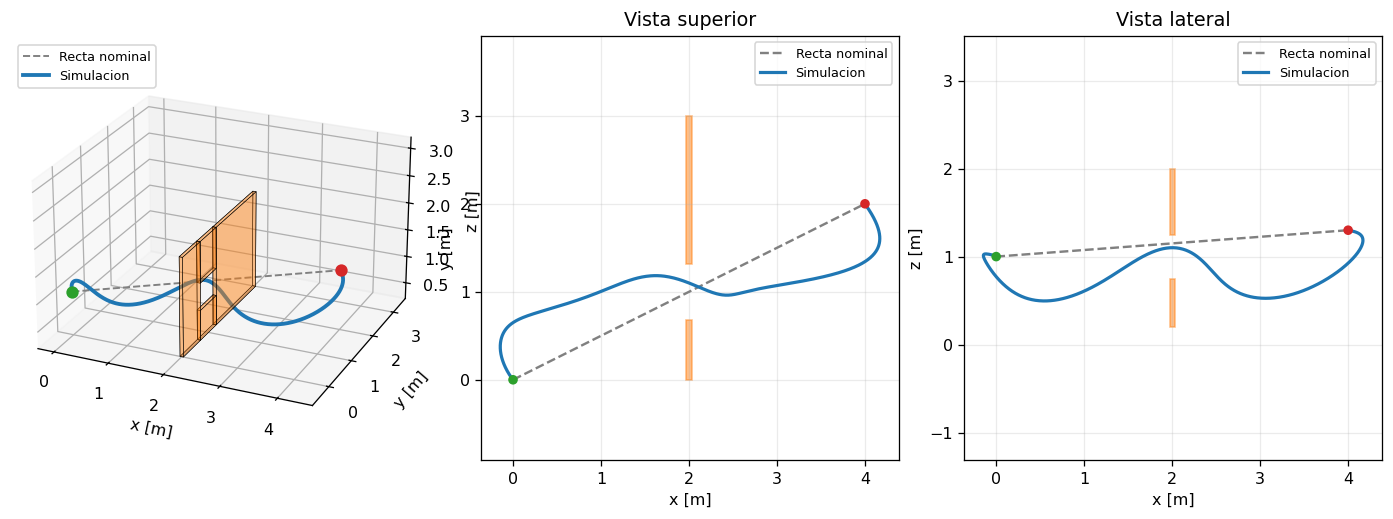

In [8]:
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# Cuboide para dibujar los bloques de la pared en 3D
def caja(ax, x0, x1, y0, y1, z0, z1, color="tab:orange", alpha=0.28):
    v = np.array([[x0,y0,z0],[x1,y0,z0],[x1,y1,z0],[x0,y1,z0],
                  [x0,y0,z1],[x1,y0,z1],[x1,y1,z1],[x0,y1,z1]])
    caras = [[0,1,2,3],[4,5,6,7],[0,1,5,4],[2,3,7,6],[1,2,6,5],[0,3,7,4]]
    ax.add_collection3d(Poly3DCollection([v[c] for c in caras], facecolor=color,
                                         edgecolor="k", linewidths=0.3, alpha=alpha))

# Pared con agujero = 4 bloques (izquierda, derecha, debajo y encima del agujero)
y_lo, y_hi = c_agujero[1]-semi_y, c_agujero[1]+semi_y
z_lo, z_hi = c_agujero[2]-semi_z, c_agujero[2]+semi_z
xa, xb = x_pared-espesor/2, x_pared+espesor/2
bloques = [(pared_y[0], y_lo, pared_z[0], pared_z[1]),
           (y_hi, pared_y[1], pared_z[0], pared_z[1]),
           (y_lo, y_hi, pared_z[0], z_lo),
           (y_lo, y_hi, z_hi, pared_z[1])]

def dibujar_pared(ax, alpha=0.28):
    for (ya, yb, za, zb) in bloques:
        caja(ax, xa, xb, ya, yb, za, zb, alpha=alpha)

fig = plt.figure(figsize=(12, 4.4), constrained_layout=True)
ax3d = fig.add_subplot(131, projection="3d")
axxy = fig.add_subplot(132)
axz = fig.add_subplot(133)

# Linea recta nominal (sin pared): solo como comparacion
p_nominal = p_ini[:, None] + (p_fin-p_ini)[:, None]*sigma[None, :]

dibujar_pared(ax3d)
# Vista superior (x,y): la pared son dos bloques con el agujero entre ellos
axxy.add_patch(plt.Rectangle((xa, pared_y[0]), espesor, y_lo-pared_y[0], color="tab:orange", alpha=0.5))
axxy.add_patch(plt.Rectangle((xa, y_hi), espesor, pared_y[1]-y_hi, color="tab:orange", alpha=0.5))
# Vista lateral (x,z): bloques por debajo y por encima del agujero
axz.add_patch(plt.Rectangle((xa, pared_z[0]), espesor, z_lo-pared_z[0], color="tab:orange", alpha=0.5))
axz.add_patch(plt.Rectangle((xa, z_hi), espesor, pared_z[1]-z_hi, color="tab:orange", alpha=0.5))

ax3d.plot(*p_nominal, "--", color="0.5", lw=1.2, label="Recta nominal")
ax3d.plot(*x_sim[0:3], color="tab:blue", lw=2.4, label="Simulacion")
ax3d.scatter(*p_ini, color="tab:green", s=45)
ax3d.scatter(*p_fin, color="tab:red", s=45)
ax3d.set(xlabel="x [m]", ylabel="y [m]", zlabel="z [m]",
         xlim=(-0.3, 4.6), ylim=(-0.7, 3.6), zlim=(0.2, 3.2))
ax3d.set_box_aspect((4.9, 4.3, 3.0))
ax3d.view_init(elev=24, azim=-66)
ax3d.legend(fontsize=8, loc="upper left")

for ax, iz, zlab, tit in [(axxy, 1, "y [m]", "Vista superior"), (axz, 2, "z [m]", "Vista lateral")]:
    ax.plot(p_nominal[0], p_nominal[iz], "--", color="0.5", label="Recta nominal")
    ax.plot(x_sim[0], x_sim[iz], color="tab:blue", lw=2, label="Simulacion")
    ax.scatter([p_ini[0], p_fin[0]], [p_ini[iz], p_fin[iz]],
               c=["tab:green", "tab:red"], s=25, zorder=4)
    ax.set(xlabel="x [m]", ylabel=zlab, title=tit)
    ax.axis("equal")
    ax.legend(fontsize=8)
mostrar_figura(fig)

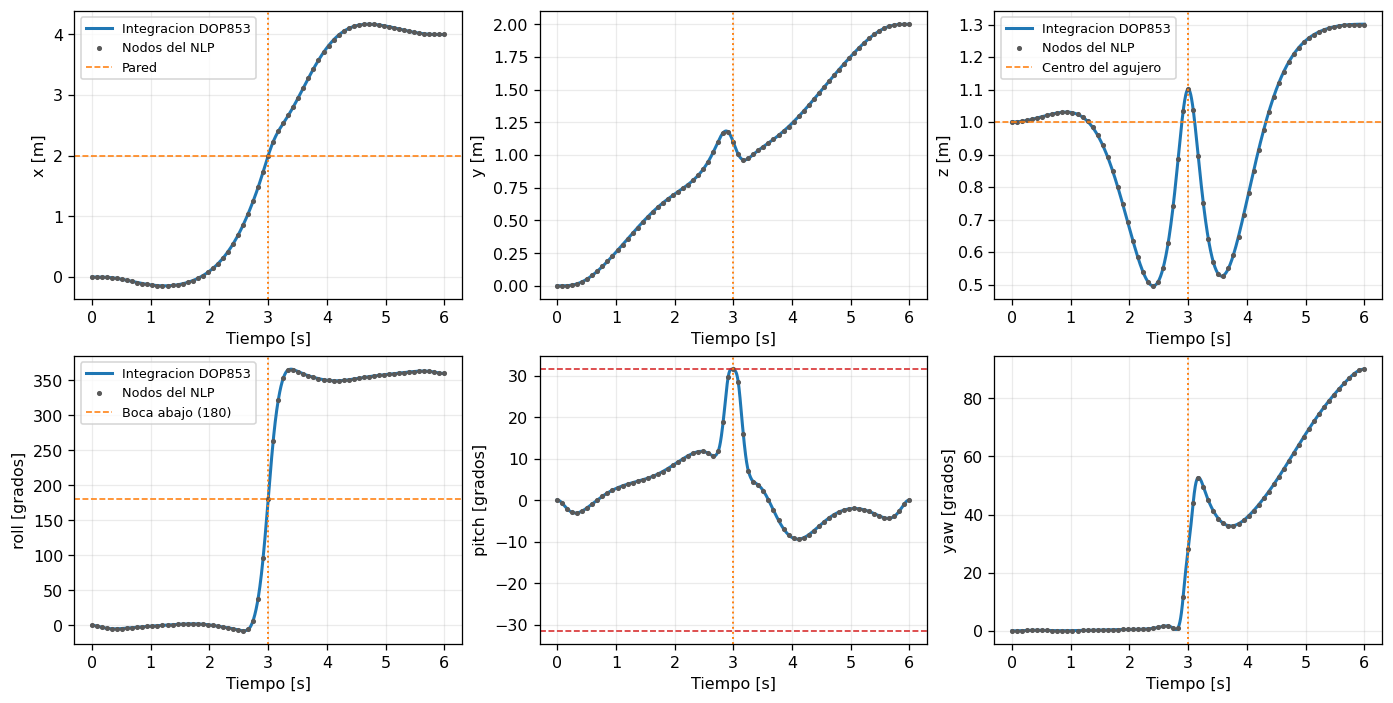

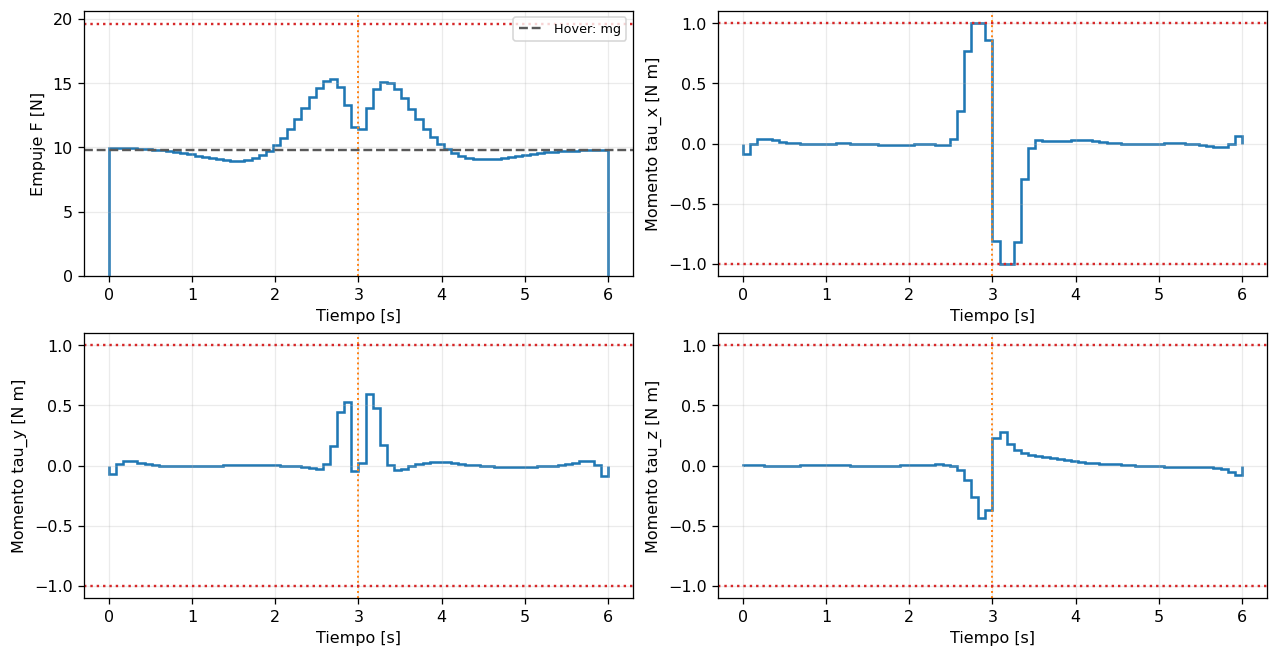

In [9]:
# Comparacion de posicion y angulos entre nodos del NLP e integracion fina
fig, axs = plt.subplots(2, 3, figsize=(12, 6), constrained_layout=True)
nom_estado = ["x [m]", "y [m]", "z [m]", "roll [grados]", "pitch [grados]", "yaw [grados]"]

for j, ax in enumerate(axs.flat):
    factor = 1.0 if j < 3 else 180/np.pi  # Angulos en grados solo al graficar
    ax.plot(t_sim, x_sim[j]*factor, color="tab:blue", lw=1.9,
            label="Integracion DOP853")
    ax.plot(t, x_opt[j]*factor, "o", color="0.35", markersize=2.2,
            label="Nodos del NLP")
    ax.axvline(t_cruce, color="tab:orange", ls=":", lw=1.2)   # instante de cruce
    ax.set(xlabel="Tiempo [s]", ylabel=nom_estado[j])
    if j == 3:   # CAMBIO: el roll recorre 0 -> 360 grados y vale 180 al cruzar
        ax.axhline(180, color="tab:orange", ls="--", lw=1, label="Boca abajo (180)")
    if j == 4:
        ax.axhline(np.degrees(angulo_max), color="tab:red", ls="--", lw=1)
        ax.axhline(-np.degrees(angulo_max), color="tab:red", ls="--", lw=1)
    if j == 0:
        ax.axhline(x_pared, color="tab:orange", ls="--", lw=1, label="Pared")
    if j == 2:
        ax.axhline(c_agujero[2], color="tab:orange", ls="--", lw=1, label="Centro del agujero")
axs[0, 0].legend(fontsize=8)
axs[0, 2].legend(fontsize=8)
axs[1, 0].legend(fontsize=8)
mostrar_figura(fig)

# Control optimo: constante a trozos en los N intervalos
fig, axs = plt.subplots(2, 2, figsize=(11, 5.6), constrained_layout=True)
nombres_u = ["Empuje F [N]", "Momento tau_x [N m]", "Momento tau_y [N m]", "Momento tau_z [N m]"]
for j, ax in enumerate(axs.flat):
    ax.stairs(u_opt[j], t, color="tab:blue", linewidth=1.6)
    ax.axvline(t_cruce, color="tab:orange", ls=":", lw=1.2)
    ax.set(xlabel="Tiempo [s]", ylabel=nombres_u[j])
    if j == 0:
        ax.axhline(m*g, ls="--", color="0.35", label="Hover: mg")
        ax.axhline(F_max, ls=":", color="tab:red")
        ax.legend(fontsize=8)
    else:
        ax.axhline(tau_max, ls=":", color="tab:red")
        ax.axhline(-tau_max, ls=":", color="tab:red")
mostrar_figura(fig)

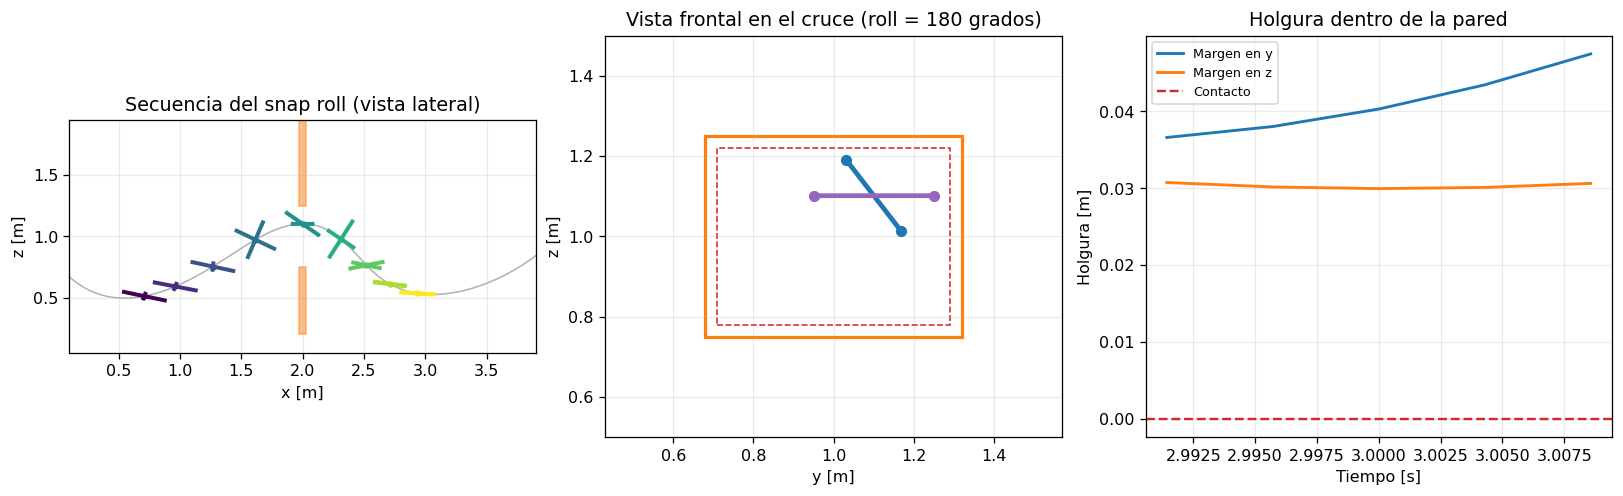

In [10]:
# Secuencia del snap roll alrededor del cruce y holguras respecto del agujero
fig, axs = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True)

# (a) Vista lateral (x,z): proyeccion de los dos brazos en 7 instantes
ax = axs[0]
ax.add_patch(plt.Rectangle((xa, pared_z[0]), espesor, z_lo-pared_z[0], color="tab:orange", alpha=0.5))
ax.add_patch(plt.Rectangle((xa, z_hi), espesor, pared_z[1]-z_hi, color="tab:orange", alpha=0.5))
ax.plot(x_sim[0], x_sim[2], color="0.7", lw=1)
for tt, col in zip(np.linspace(t_cruce-t_vuelta/2, t_cruce+t_vuelta/2, 9), plt.cm.viridis(np.linspace(0, 1, 9))):
    jj = np.argmin(np.abs(t_sim - tt))
    pos = x_sim[0:3, jj]
    for b in ejes_cuerpo_np(x_sim[:, jj]):
        ax.plot([pos[0]-brazo*b[0], pos[0]+brazo*b[0]],
                [pos[2]-brazo*b[2], pos[2]+brazo*b[2]], color=col, lw=2.5)
    ax.plot(pos[0], pos[2], "o", color=col, ms=3)
ax.set(xlabel="x [m]", ylabel="z [m]", title="Secuencia del snap roll (vista lateral)")
ax.set_xlim(x_pared-(v_cruce*t_vuelta/2+0.4), x_pared+(v_cruce*t_vuelta/2+0.4)); ax.set_ylim(z_lo-0.7, z_hi+0.7); ax.set_aspect("equal")

# (b) Vista frontal (y,z) en el cruce: el agujero y las puntas de los rotores
ax = axs[1]
ax.add_patch(plt.Rectangle((y_lo, z_lo), 2*semi_y, 2*semi_z, fill=False, ec="tab:orange", lw=2))
ax.add_patch(plt.Rectangle((y_lo+radio_rotor, z_lo+radio_rotor), 2*(semi_y-radio_rotor),
                           2*(semi_z-radio_rotor), fill=False, ec="tab:red", ls="--", lw=1))
pos = x_sim[0:3, j_cruce]
for b, c_ in zip(ejes_cuerpo_np(x_sim[:, j_cruce]), ("tab:blue", "tab:purple")):
    ax.plot([pos[1]-brazo*b[1], pos[1]+brazo*b[1]], [pos[2]-brazo*b[2], pos[2]+brazo*b[2]],
            color=c_, lw=3, marker="o")
ax.set(xlabel="y [m]", ylabel="z [m]", title=f"Vista frontal en el cruce (roll = {roll_cruce:.0f} grados)")
ax.set_xlim(y_lo-0.25, y_hi+0.25); ax.set_ylim(z_lo-0.25, z_hi+0.25); ax.set_aspect("equal")

# (c) Margen de las puntas respecto del borde, mientras el robot esta dentro de la losa
ax = axs[2]
ax.plot(t_sim[dentro], marg[0, dentro], lw=1.8, label="Margen en y")
ax.plot(t_sim[dentro], marg[1, dentro], lw=1.8, label="Margen en z")
ax.axhline(0, ls="--", color="tab:red", label="Contacto")
ax.set(xlabel="Tiempo [s]", ylabel="Holgura [m]", title="Holgura dentro de la pared")
ax.legend(fontsize=8)
mostrar_figura(fig)

## 4. Visualización del movimiento

Los dos brazos del quadcopter se dibujan como segmentos del sistema del cuerpo y se rotan al espacio mediante $R(\phi,\theta,\psi)$. El punto **rojo** marca el extremo delantero del brazo $x$ del cuerpo, y el brazo azul/morado permite ver cuándo el vehículo está **boca abajo**. El trazo azul muestra la trayectoria; los bloques naranjas son la pared con su agujero. La animación usa los estados de la **simulación independiente**.

In [11]:
# Rotacion del marco del cuerpo hacia el marco inercial, segun ZYX
def rotacion_cuerpo(phi, theta, psi):
    cf, sf = np.cos(phi), np.sin(phi)
    ct, st = np.cos(theta), np.sin(theta)
    cp, sp = np.cos(psi), np.sin(psi)
    return np.array([
        [cp*ct, cp*st*sf-sp*cf, cp*st*cf+sp*sf],
        [sp*ct, sp*st*sf+cp*cf, sp*st*cf-cp*sf],
        [-st,   ct*sf,           ct*cf]
    ])

# Mas frames cerca del cruce para ver bien el giro
indices = np.unique(np.r_[np.linspace(0, len(t_sim)-1, 55, dtype=int),
                          np.linspace(np.argmin(np.abs(t_sim-(t_cruce-t_vuelta))),
                                      np.argmin(np.abs(t_sim-(t_cruce+t_vuelta))), 30, dtype=int)])

fig = plt.figure(figsize=(8, 5.5), dpi=80)
ax = fig.add_subplot(111, projection="3d")
dibujar_pared(ax, alpha=0.30)                       # CAMBIO: pared en lugar de esferas
ax.plot(*x_sim[0:3], color="0.72", ls="--", lw=1, alpha=0.8)
ax.scatter(*p_ini, color="tab:green", s=48, label="Inicio")
ax.scatter(*p_fin, color="tab:red", s=48, label="Objetivo")

linea_trayectoria, = ax.plot([], [], [], color="tab:blue", lw=2.2)
brazo_x, = ax.plot([], [], [], color="tab:blue", lw=3, marker="o", markersize=5)
brazo_y, = ax.plot([], [], [], color="tab:purple", lw=3, marker="o", markersize=5)
centro_robot, = ax.plot([], [], [], "ko", markersize=5)
nariz, = ax.plot([], [], [], "o", color="red", markersize=7)   # CAMBIO: frente del cuerpo

ax.set(xlabel="x [m]", ylabel="y [m]", zlabel="z [m]",
       xlim=(-0.4, 4.6), ylim=(-0.8, 3.6), zlim=(0.2, 3.2))
ax.set_box_aspect((5.0, 4.4, 3.0))
ax.view_init(elev=22, azim=-62)
ax.legend(loc="upper left", fontsize=9)

def actualizar(frame):
    j = indices[frame]
    pos = x_sim[0:3, j]
    phi, theta, psi = x_sim[3:6, j]
    R = rotacion_cuerpo(phi, theta, psi)

    dx = R @ np.array([brazo, 0, 0])
    dy = R @ np.array([0, brazo, 0])
    px = np.column_stack((pos-dx, pos+dx))
    py = np.column_stack((pos-dy, pos+dy))

    brazo_x.set_data_3d(px[0], px[1], px[2])
    brazo_y.set_data_3d(py[0], py[1], py[2])
    centro_robot.set_data_3d([pos[0]], [pos[1]], [pos[2]])
    nariz.set_data_3d([pos[0]+dx[0]], [pos[1]+dx[1]], [pos[2]+dx[2]])
    linea_trayectoria.set_data_3d(x_sim[0, :j+1], x_sim[1, :j+1], x_sim[2, :j+1])
    ax.set_title(f"Snap roll | t = {t_sim[j]:.2f} s | roll = {np.degrees(phi):.0f} gr | yaw = {np.degrees(psi):.0f} gr")
    return linea_trayectoria, brazo_x, brazo_y, centro_robot, nariz

animacion = FuncAnimation(fig, actualizar, frames=len(indices), interval=65,
                         blit=False, repeat=True)
plt.close(fig)
display(HTML(animacion.to_jshtml(fps=17, default_mode="loop")))

Referencias: [CasADi](https://web.casadi.org/docs/), [IPOPT](https://coin-or.github.io/Ipopt/), [SciPy `solve_ivp`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html).